# Model Building

### Import Libraries and loding data

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    balanced_accuracy_score
)

from imblearn.ensemble import BalancedRandomForestClassifier

In [2]:
df = pd.read_csv("../Data/Modeling_Data.csv")

print("Dataset shape:", df.shape)

df.head()

Dataset shape: (38018, 41)


,sy_snum,sy_pnum,st_teff,st_rad,st_radlim,st_logglim,ra,dec,sy_dist,sy_disterr1,...,log_sy_dist,v_mag_error_mean,k_mag_error_mean,gaia_mag_error_mean,distance_error_mean,distance_relative_error,sky_x,sky_y,sky_z,stellar_class
0,2.0,1.0,4742.000,19.000,0.0,0.0,185.178779,17.793252,93.1846,1.9238,...,1.969344,0.023,0.346,0.003848,1.9238,0.020645,-0.948279,-0.085946,0.305583,Evolved Subgiant/Giant
1,2.0,1.0,4741.436,16.626,0.0,0.0,185.178779,17.793252,93.1846,1.9238,...,1.969344,0.023,0.346,0.003848,1.9238,0.020645,-0.948279,-0.085946,0.305583,Evolved Subgiant/Giant
2,2.0,1.0,4830.000,3.990,0.0,0.0,185.178779,17.793252,93.1846,1.9238,...,1.969344,0.023,0.346,0.003848,1.9238,0.020645,-0.948279,-0.085946,0.305583,Evolved Subgiant/Giant
3,2.0,1.0,4705.000,15.780,0.0,0.0,185.178779,17.793252,93.1846,1.9238,...,1.969344,0.023,0.346,0.003848,1.9238,0.020645,-0.948279,-0.085946,0.305583,Evolved Subgiant/Giant
4,2.0,1.0,4741.436,16.626,0.0,0.0,185.178779,17.793252,93.1846,1.9238,...,1.969344,0.023,0.346,0.003848,1.9238,0.020645,-0.948279,-0.085946,0.305583,Evolved Subgiant/Giant


In [3]:
df = df.drop_duplicates()

In [4]:
print("Dataset shape:", df.shape)

Dataset shape: (28485, 41)


In [5]:

print(df["sy_pnum"].value_counts())

sy_pnum
1.0    20456
2.0     5220
3.0     2000
4.0      809
Name: count, dtype: int64


In [6]:
# Identify numerical and categorical columns
num_cols = [
    col for col in df.select_dtypes(include=np.number).columns
]

cat_cols = [
    col for col in df.select_dtypes(exclude=np.number).columns
]



In [7]:
num_cols

['sy_snum',
 'sy_pnum',
 'st_teff',
 'st_rad',
 'st_radlim',
 'st_logglim',
 'ra',
 'dec',
 'sy_dist',
 'sy_disterr1',
 'sy_disterr2',
 'sy_vmag',
 'sy_vmagerr1',
 'sy_vmagerr2',
 'sy_kmag',
 'sy_kmagerr1',
 'sy_kmagerr2',
 'sy_gaiamag',
 'sy_gaiamagerr1',
 'sy_gaiamagerr2',
 'color_v_k',
 'color_gaia_v',
 'color_gaia_k',
 'distance_modulus',
 'absolute_v_mag',
 'absolute_k_mag',
 'absolute_gaia_mag',
 'stellar_luminosity',
 'log_stellar_luminosity',
 'log_st_teff',
 'log_st_rad',
 'log_sy_dist',
 'v_mag_error_mean',
 'k_mag_error_mean',
 'gaia_mag_error_mean',
 'distance_error_mean',
 'distance_relative_error',
 'sky_x',
 'sky_y',
 'sky_z']

In [8]:
df[cat_cols].value_counts()

stellar_class         
Unclassified              7845
G-type Solar Analog       7298
K-dwarf                   6171
Evolved Subgiant/Giant    4349
F-type                    1803
M-dwarf                   1019
Name: count, dtype: int64

In [9]:
X = df.drop(columns=["sy_pnum","stellar_class"])

y = df["sy_pnum"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (28485, 39)
Target shape: (28485,)


In [10]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training:", X_train.shape)
print("Testing:", X_test.shape)

Training: (22788, 39)
Testing: (5697, 39)


In [11]:
numeric_features = X_train.select_dtypes(
    include=np.number
).columns.tolist()

categorical_features = X_train.select_dtypes(
    exclude=np.number
).columns.tolist()


numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])


categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])


preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

In [12]:
classifier = BalancedRandomForestClassifier(
    n_estimators=400,
    sampling_strategy="all",
    replacement=True,
    random_state=42,
    n_jobs=-1
)

In [13]:
model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", classifier)
])

In [14]:
model.fit(X_train, y_train)

print("Model training completed!")

Model training completed!


In [15]:
y_pred = model.predict(X_test)

In [16]:
print("Accuracy:", accuracy_score(y_test, y_pred))

print(
    "Balanced Accuracy:",
    balanced_accuracy_score(y_test, y_pred)
)

print(
    "Macro F1 Score:",
    f1_score(y_test, y_pred, average="macro")
)

print("\nClassification Report:\n")

print(
    classification_report(
        y_test,
        y_pred,
        zero_division=0
    )
)

Accuracy: 0.9541864139020537
Balanced Accuracy: 0.9715133092827822
Macro F1 Score: 0.9433773443955327

Classification Report:

              precision    recall  f1-score   support

         1.0       0.99      0.95      0.97      4091
         2.0       0.86      0.96      0.91      1044
         3.0       0.92      0.98      0.95       400
         4.0       0.91      1.00      0.95       162

    accuracy                           0.95      5697
   macro avg       0.92      0.97      0.94      5697
weighted avg       0.96      0.95      0.95      5697



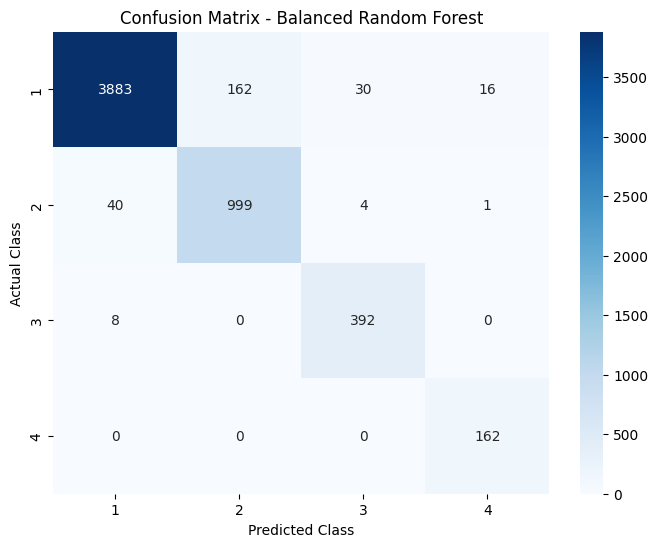

In [17]:
cm = confusion_matrix(
    y_test,
    y_pred,
    labels=[1, 2, 3, 4]
)

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=[1, 2, 3, 4],
    yticklabels=[1, 2, 3, 4]
)

plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.title("Confusion Matrix - Balanced Random Forest")

plt.show()

In [18]:
feature_names = (
    model.named_steps["preprocessor"]
    .get_feature_names_out()
)

importances = (
    model.named_steps["classifier"]
    .feature_importances_
)

feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importances
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

print(feature_importance.head(20))

                         Feature  Importance
36                    num__sky_x    0.043854
5                        num__ra    0.042563
37                    num__sky_y    0.038185
20             num__color_gaia_v    0.037374
18           num__sy_gaiamagerr2    0.035826
17           num__sy_gaiamagerr1    0.035587
6                       num__dec    0.034927
38                    num__sky_z    0.034660
33      num__gaia_mag_error_mean    0.034303
21             num__color_gaia_k    0.034265
24           num__absolute_k_mag    0.033209
35  num__distance_relative_error    0.032273
19                num__color_v_k    0.031175
13                  num__sy_kmag    0.030450
23           num__absolute_v_mag    0.029520
25        num__absolute_gaia_mag    0.028957
16               num__sy_gaiamag    0.027722
10                  num__sy_vmag    0.027710
11              num__sy_vmagerr1    0.026218
9               num__sy_disterr2    0.026196


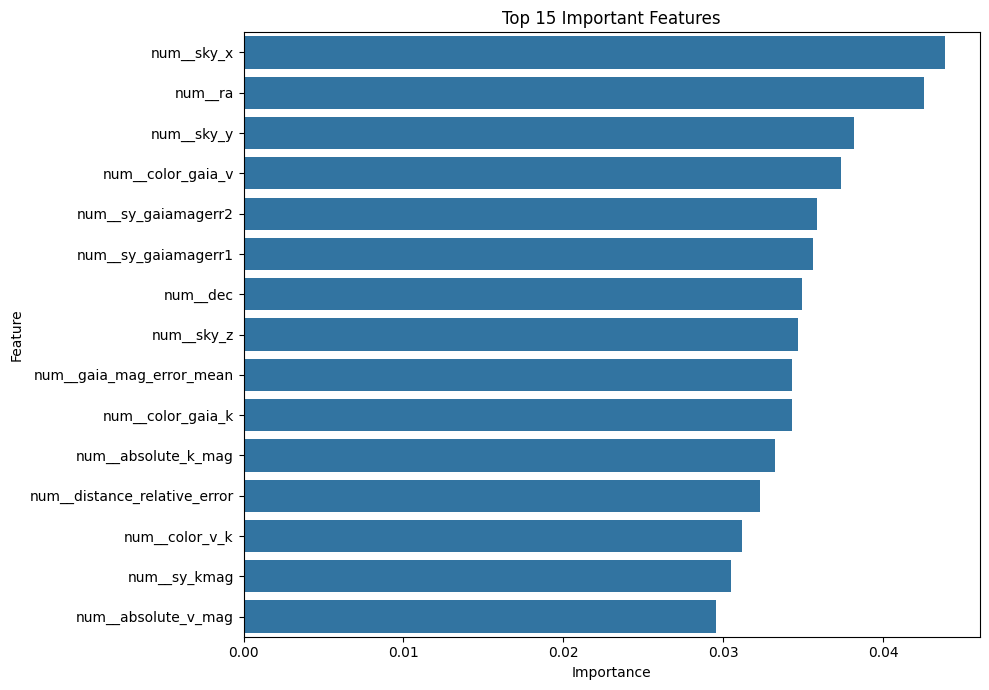

In [19]:
plt.figure(figsize=(10, 7))

sns.barplot(
    data=feature_importance.head(15),
    x="Importance",
    y="Feature"
)

plt.title("Top 15 Important Features")
plt.tight_layout()
plt.show()